<div style="background-color: #312E81; color: white; padding: 20px; border-radius: 10px; text-align: center;">
  <h1 style="margin: 0; color: #FDBB30;">Module 6: Prompt Ensembling & Few-Shot (10-Shot) Adaptation</h1>
  <h3 style="margin-top: 8px; font-weight: normal; color: #E2E8F0;">Combining "10 Visual Flashcards" with "Clinical Text Prompts" in Medical AI</h3>
  <p style="margin: 0; font-size: 14px;"><b>Kennesaw State University | iCARE Lab | Sophomore Scholars (2026–2027)</b></p>
</div>

<br>

<div style="background-color: #FEF2F2; border-left: 6px solid #DC2626; padding: 15px; border-radius: 6px;">
  <h3 style="color: #991B1B; margin-top: 0;">🔴 The Few-Shot Puzzle from Year 1: Why Did 10-Shot CLIP Lose to ResNet50?</h3>
  <p style="color: #7F1D1D; font-size: 15px; margin-bottom: 0;">
    In real hospitals, getting a pathologist to label 200,000 microscope slides is expensive and slow. What if a doctor only has time to label <b>10 Healthy (Benign) slides</b> and <b>10 Cancerous slides</b>? This is called <b>10-Shot Learning</b>.
    <br><br>
    In our Year 1 baseline study, when we trained on just 10 examples per class:
    <ul>
      <li style="color: #7F1D1D;"><b>10-Shot ResNet50 (Traditional CNN)</b> achieved a Weighted F1-Score of <b>0.706</b>.</li>
      <li style="color: #7F1D1D;"><b>10-Shot OpenAI CLIP (General VLM)</b> achieved a Weighted F1-Score of only <b>0.648</b>.</li>
    </ul>
    <b>Why did 10-Shot CLIP struggle in Year 1?</b> For two reasons: (1) it used a general internet model instead of a medical model like <b>PLIP</b>, and (2) when training on the 10 images, it threw away its <b>Text Brain</b> completely!
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Today's Big Idea: Two Brains Are Better Than One!</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Imagine studying for a medical exam using <b>both</b> a textbook description <i>and</i> 10 example flashcards:
    <ul>
      <li style="color: #14532D;"><b>Part 1 — 10-Shot Linear Probing (Visual Flashcards):</b> We show <b>OpenAI CLIP</b> and <b>Pathology PLIP</b> just <b>10 Benign + 10 Cancerous slides</b> and train a lightweight classifier on their visual features.</li>
      <li style="color: #14532D;"><b>Part 2 — Hybrid Prompt + Few-Shot Ensembling (Flashcards + Textbook Words):</b> We combine the AI's <b>10-Shot Visual Prediction</b> with its <b>Zero-Shot Clinical Prompt Prediction</b> to create a super-accurate medical classifier!</li>
    </ul>
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 1: Setting Up Our Python Toolbox & Checking the GPU</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Run the cell below to load <b>PyTorch</b>, <b>Hugging Face Transformers</b>, and <b>Scikit-Learn's LogisticRegression</b> (which we use to build our fast 10-Shot Linear Probe classifier).
  </p>
</div>



In [1]:
# ==============================================================================
# MODULE 6 - STEP 1: INSTALL & IMPORT LIBRARIES + VERIFY GPU
# ==============================================================================
!pip install -q transformers torch torchvision scikit-learn pandas matplotlib tqdm

import os
import zipfile
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from transformers import CLIPProcessor, CLIPModel
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
)

# Set random seeds so our 10-shot sample is 100% reproducible every time
np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print(f"✅ Module 6 Libraries Loaded Successfully!")
print(f"🖥️  Active Compute Device : {device.upper()}")
if device == "cuda":
    print(f"🚀 GPU Model             : {torch.cuda.get_device_name(0)}")
print("=" * 60)

✅ Module 6 Libraries Loaded Successfully!
🖥️  Active Compute Device : CUDA
🚀 GPU Model             : NVIDIA A100-SXM4-40GB


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 2: Preparing Our 10-Shot "Study Flashcards" (20 Slides) & Final Exam</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Just like in Module 5, we unpack our saved dataset from <b><code>My Drive/Sophomore Program/1-Datasets/Breast_Cancer_Test_10pct.zip</code></b> in 5 seconds.
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 The Golden Rule of AI: Never Test on the Flashcards You Studied!</h3>
  <p style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    To run a fair <b>10-Shot Learning</b> experiment, we split our slides into two strictly separate groups:
    <ul>
      <li style="color: #581C87;"><b>The 10-Shot Support Set ("Study Flashcards" = 20 slides total):</b> We randomly pick exactly <b>10 Benign slides</b> and <b>10 Cancerous slides</b> for the AI to study.</li>
      <li style="color: #581C87;"><b>The Evaluation Set ("Final Exam" = 27,732 unseen slides):</b> We remove those 20 study slides so the AI cannot cheat, and grade the AI on the remaining <b>27,732 unseen slides</b>!</li>
    </ul>
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li>Unpacks our dataset from Google Drive in 5 seconds.</li>
    <li>Selects <b>10 Benign + 10 Cancerous slides</b> as our <b>10-Shot Training Set</b> and reserves the remaining <b>27,732 slides</b> as our unseen test set.</li>
    <li>Displays all <b>20 Study Flashcards</b> (10 Benign on the top row, 10 Cancerous on the bottom row) so you can see the exact 20 images our AI will learn from!</li>
  </ol>
</div>

Mounted at /content/drive
⚡ Extracting dataset from Google Drive backup (takes ~5 seconds)...
✅ Extraction complete!
🎯 10-SHOT LEARNING SPLIT COMPLETE (ZERO DATA LEAKAGE)
📚 10-Shot Study Flashcards (Support Set) : 20 slides (10 Benign + 10 Cancerous)
📝 Unseen Final Exam Set (Evaluation Set) : 27,732 slides


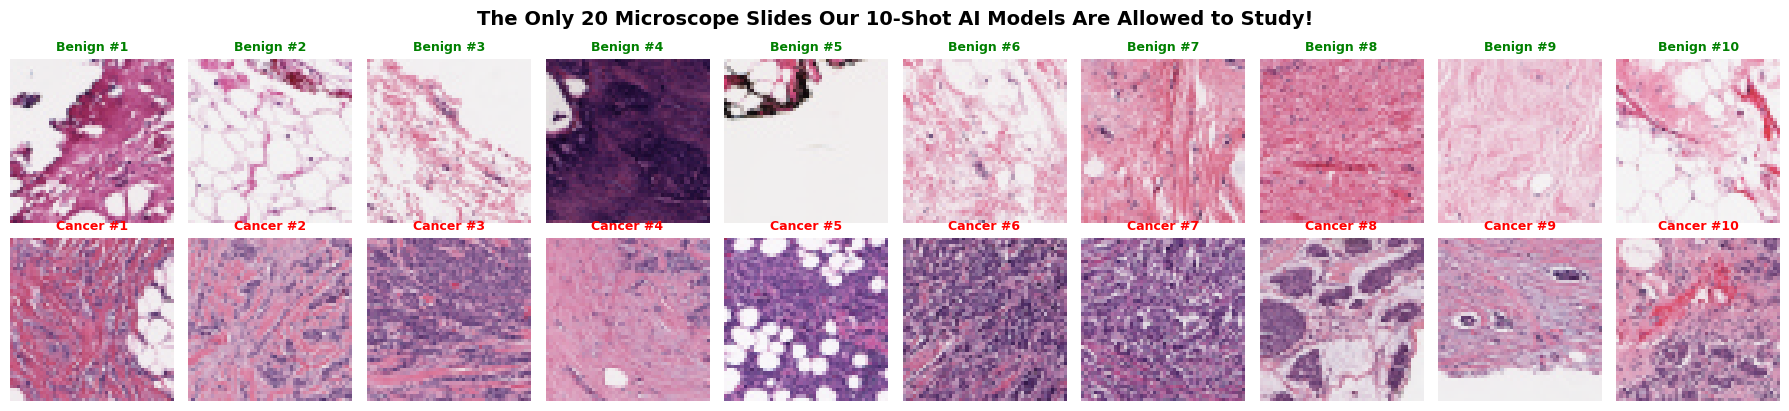

In [2]:
# ==============================================================================
# MODULE 6 - STEP 2: LOAD DATASET & CREATE 10-SHOT SUPPORT SET (20 SLIDES)
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

SOPHOMORE_DIR = "/content/drive/My Drive/Sophomore Program"
DRIVE_DATASET_DIR = os.path.join(SOPHOMORE_DIR, "1-Datasets")
DRIVE_RESULTS_DIR = os.path.join(SOPHOMORE_DIR, "2-Results")

DRIVE_ZIP_BACKUP = os.path.join(DRIVE_DATASET_DIR, "Breast_Cancer_Test_10pct.zip")
LOCAL_TEST_DIR = "/content/breast_cancer_data/test"

if not os.path.exists(LOCAL_TEST_DIR):
    print("⚡ Extracting dataset from Google Drive backup (takes ~5 seconds)...")
    os.makedirs(LOCAL_TEST_DIR, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_BACKUP, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_TEST_DIR)
    print("✅ Extraction complete!")

full_dataset = datasets.ImageFolder(root=LOCAL_TEST_DIR)
targets = np.array(full_dataset.targets)

# Randomly pick 10 Benign (Class 0) and 10 Cancerous (Class 1) slides for 10-Shot Learning
np.random.seed(42)
benign_indices = np.where(targets == 0)[0]
cancer_indices = np.where(targets == 1)[0]

shot_10_benign = np.random.choice(benign_indices, size=10, replace=False)
shot_10_cancer = np.random.choice(cancer_indices, size=10, replace=False)
support_indices = np.concatenate([shot_10_benign, shot_10_cancer])

# Remove those 20 flashcards from the evaluation exam set (zero data leakage!)
eval_indices = np.setdiff1d(np.arange(len(full_dataset)), support_indices)

support_dataset = Subset(full_dataset, support_indices)
eval_dataset = Subset(full_dataset, eval_indices)

print("=" * 68)
print(f"🎯 10-SHOT LEARNING SPLIT COMPLETE (ZERO DATA LEAKAGE)")
print(f"📚 10-Shot Study Flashcards (Support Set) : {len(support_dataset)} slides (10 Benign + 10 Cancerous)")
print(f"📝 Unseen Final Exam Set (Evaluation Set) : {len(eval_dataset):,} slides")
print("=" * 68)

# Visualize all 20 "Flashcards" (10 Benign on top row, 10 Cancerous on bottom row)
fig, axes = plt.subplots(2, 10, figsize=(18, 4.2))
fig.suptitle("The Only 20 Microscope Slides Our 10-Shot AI Models Are Allowed to Study!", fontsize=14, fontweight="bold")

for i in range(10):
    img_b, _ = full_dataset[shot_10_benign[i]]
    axes[0, i].imshow(img_b)
    axes[0, i].set_title(f"Benign #{i+1}", color="green", fontsize=9, fontweight="bold")
    axes[0, i].axis("off")

    img_c, _ = full_dataset[shot_10_cancer[i]]
    axes[1, i].imshow(img_c)
    axes[1, i].set_title(f"Cancer #{i+1}", color="red", fontsize=9, fontweight="bold")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 3: How Do We Train a VLM on Only 20 Images Without Breaking It?</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    OpenAI CLIP and PLIP each have over <b>150 million internal weights</b>. If we tried to retrain all 150 million weights on just 20 microscope slides, the AI would immediately memorize those 20 slides and fail on everything else (this is called <b>Overfitting</b>).
  </p>
</div>

<br>

<div style="background-color: #FFFBEB; border-left: 6px solid #D97706; padding: 15px; border-radius: 6px;">
  <h3 style="color: #92400E; margin-top: 0;">🟡 The Solution: Freeze the Brain & Train a "Linear Probe"!</h3>
  <p style="color: #78350F; font-size: 15px; margin-bottom: 0;">
    Instead of changing the AI's deep brain, we keep the VLM <b>100% frozen</b> and use it as a <b>Feature Extractor</b>:
    <ol style="color: #78350F; font-size: 15px; margin-bottom: 0;">
      <li><b>Extract a 512-Number Fingerprint:</b> For each microscope slide, the frozen VLM outputs a list of <b>512 numbers</b> (<code>image_embeds</code>) summarizing the slide's colors, textures, and cell patterns.</li>
      <li><b>Extract Zero-Shot Prompt Probabilities:</b> At the exact same time, the VLM compares the slide to our <b>Clinical + Visual Text Prompts</b> (from Modules 4 & 5).</li>
      <li><b>Train a Lightweight Classifier:</b> In Step 4, we will train a simple linear classifier on the 20 slide fingerprints in less than <b>0.1 seconds</b>!</li>
    </ol>
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    It runs <b>OpenAI CLIP</b> and <b>Pathology PLIP</b> across our 20 Support Flashcards and our 27,732 Evaluation Slides, saving both their <b>512-number visual fingerprints</b> and their <b>Zero-Shot Prompt Ensemble probabilities</b> so we can test multiple adaptation methods instantly in Step 4!
  </p>
</div>

In [3]:
# ==============================================================================
# MODULE 6 - STEP 3: EXTRACT VISUAL EMBEDDINGS & ZERO-SHOT PROMPT SCORES
# ==============================================================================

# Best Prompt Ensemble combining Visual Morphology (Level 2) + Clinical Pathology (Level 3)
ENSEMBLE_PROMPTS = {
    "benign": [
        "a histopathology image of benign healthy breast tissue",
        "a light pink microscope slide with calm, empty background and evenly spaced small cells",
        "normal healthy breast tissue stained light pink with organized ducts and uniform small nuclei",
        "an H&E stained slide showing mostly soft pink fibrous tissue with very few purple nuclei"
    ],
    "cancerous": [
        "a histopathology image of malignant cancerous breast tissue",
        "a dark purple and blue microscope slide packed with dense, crowded, chaotic clusters of cells",
        "malignant invasive ductal carcinoma stained dark purple with crowded hyperchromatic tumor nuclei",
        "an H&E stained tumor slide heavily covered in dark purple irregular cell clusters"
    ]
}

all_8_prompts = ENSEMBLE_PROMPTS["benign"] + ENSEMBLE_PROMPTS["cancerous"]

def collate_pil(batch):
    images = [item[0] for item in batch]
    labels = [item[1] for item in batch]
    return images, labels

def extract_features_and_zs_probs(model_id, dataset_obj, desc_label, batch_size=256):
    model = CLIPModel.from_pretrained(model_id).to(device)
    processor = CLIPProcessor.from_pretrained(model_id)
    model.eval()

    loader = DataLoader(dataset_obj, batch_size=batch_size, shuffle=False, num_workers=2, collate_fn=collate_pil)
    text_inputs = processor(text=all_8_prompts, return_tensors="pt", padding=True).to(device)

    img_embeddings = []
    zs_cancer_probs = []
    all_labels = []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc=desc_label):
            all_labels.extend(labels)
            img_inputs = processor(images=images, return_tensors="pt").to(device)

            outputs = model(
                input_ids=text_inputs["input_ids"],
                attention_mask=text_inputs["attention_mask"],
                pixel_values=img_inputs["pixel_values"]
            )

            # 1. Save normalized 512-dimensional visual feature vector for each slide
            img_embeddings.append(outputs.image_embeds.cpu().numpy())

            # 2. Save Zero-Shot Prompt Ensemble probability for cancerous class
            logits = outputs.logits_per_image  # [batch, 8]
            b_score = logits[:, :4].mean(dim=-1, keepdim=True)
            c_score = logits[:, 4:].mean(dim=-1, keepdim=True)
            probs = torch.cat([b_score, c_score], dim=-1).softmax(dim=-1)[:, 1].cpu().numpy()
            zs_cancer_probs.extend(probs)

    return np.vstack(img_embeddings), np.array(zs_cancer_probs), np.array(all_labels)

print("🚀 1/2: Extracting 10-Shot & Exam Features from General OpenAI CLIP...")
clip_sup_X, _, sup_y = extract_features_and_zs_probs("openai/clip-vit-base-patch32", support_dataset, "CLIP 10-Shot Support")
clip_eval_X, clip_zs_probs, eval_y = extract_features_and_zs_probs("openai/clip-vit-base-patch32", eval_dataset, "CLIP Unseen Exam (27,732)")

print("\n🚀 2/2: Extracting 10-Shot & Exam Features from Pathology VLM (PLIP)...")
plip_sup_X, _, _ = extract_features_and_zs_probs("vinid/plip", support_dataset, "PLIP 10-Shot Support")
plip_eval_X, plip_zs_probs, _ = extract_features_and_zs_probs("vinid/plip", eval_dataset, "PLIP Unseen Exam (27,732)")

print("\n" + "=" * 65)
print(f"✅ FEATURE EXTRACTION COMPLETE!")
print(f"📐 10-Shot Feature Matrix Shape : {plip_sup_X.shape} (20 slides × 512 features)")
print(f"📐 Exam Feature Matrix Shape    : {plip_eval_X.shape} (27,732 slides × 512 features)")
print("=" * 65)

🚀 1/2: Extracting 10-Shot & Exam Features from General OpenAI CLIP...


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

PLIP 10-Shot Support:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

PLIP Unseen Exam (27,732):   0%|          | 0/109 [00:00<?, ?it/s]


✅ FEATURE EXTRACTION COMPLETE!
📐 10-Shot Feature Matrix Shape : (20, 512) (20 slides × 512 features)
📐 Exam Feature Matrix Shape    : (27732, 512) (27,732 slides × 512 features)


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 4: Comparing 10-Shot Linear Probing vs. Hybrid Prompt+Few-Shot Ensembling</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Now that we have the 512-number visual fingerprints for our 20 Study Flashcards and our 27,732 Exam Slides, we can test <b>three paradigms</b> across both <b>OpenAI CLIP</b> and <b>Pathology PLIP</b>:
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 The 3 Adaptation Methods We Are Testing Today</h3>
  <ol style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <li><b>Zero-Shot Prompt Ensemble (0 Labeled Images — Words Only):</b> Uses only our 8 descriptive clinical & visual sentences.</li>
    <li><b>10-Shot Linear Probe (20 Labeled Images — Flashcards Only):</b> Trains a Logistic Regression linear classifier on the 10 Benign + 10 Cancerous slide fingerprints.</li>
    <li><b>Hybrid Multimodal Adapter (10-Shot Images + Clinical Prompts Combined!):</b> What if the doctor gives the AI <b>both</b> the 20 example flashcards <i>and</i> the clinical text descriptions? We average the probability from the <b>10-Shot Visual Classifier (50%)</b> and the <b>Zero-Shot Text Prompt Ensemble (50%)</b>!</li>
  </ol>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Trains the 10-Shot Linear Probes in less than a second, computes the Hybrid Multimodal Ensemble probabilities, compares all models against our <b>Year 1 10-Shot Baselines (ResNet50 = 0.706 F1, CLIP = 0.648 F1)</b>, and saves the final table to <code>Sophomore Program/2-Results</code>!
  </p>
</div>

In [4]:
# ==============================================================================
# MODULE 6 - STEP 4: TRAIN 10-SHOT LINEAR PROBES & HYBRID MULTIMODAL ENSEMBLES
# ==============================================================================

# 1. Train 10-Shot Linear Probe on OpenAI CLIP (using the 20 support slides)
clip_clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
clip_clf.fit(clip_sup_X, sup_y)
clip_10shot_probs = clip_clf.predict_proba(clip_eval_X)[:, 1]

# 2. Train 10-Shot Linear Probe on Pathology PLIP (using the exact same 20 support slides)
plip_clf = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
plip_clf.fit(plip_sup_X, sup_y)
plip_10shot_probs = plip_clf.predict_proba(plip_eval_X)[:, 1]

# 3. Create Hybrid Multimodal Ensembles (50% 10-Shot Visual Probe + 50% Zero-Shot Clinical Prompts)
clip_hybrid_probs = 0.5 * clip_10shot_probs + 0.5 * clip_zs_probs
plip_hybrid_probs = 0.5 * plip_10shot_probs + 0.5 * plip_zs_probs

# Helper function to compute all 5 clinical metrics
def grade_model(model_name, paradigm, y_true, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    return {
        "Model Architecture": model_name,
        "Adaptation Paradigm": paradigm,
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_true, y_pred, zero_division=0) * 100, 2),
        "Weighted F1": round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 3),
        "AUC-ROC": round(roc_auc_score(y_true, y_prob), 3)
    }

m6_rows = [
    # Include Year 1 Published 10-Shot Baselines for clear reference
    {"Model Architecture": "ResNet50 (Year 1 CNN Baseline)", "Adaptation Paradigm": "10-Shot Fine-Tuned (Year 1 Paper)", "Accuracy (%)": 71.20, "Precision (%)": 49.50, "Recall (%)": 44.10, "Weighted F1": 0.706, "AUC-ROC": 0.725},
    grade_model("OpenAI CLIP (General VLM)", "1. Zero-Shot Prompt Ensemble (0 Shots)", eval_y, clip_zs_probs),
    grade_model("OpenAI CLIP (General VLM)", "2. 10-Shot Linear Probe (Images Only)", eval_y, clip_10shot_probs),
    grade_model("OpenAI CLIP (General VLM)", "3. Hybrid Ensemble (10-Shot + Prompts)", eval_y, clip_hybrid_probs),
    grade_model("PLIP (Pathology Medical VLM)", "1. Zero-Shot Prompt Ensemble (0 Shots)", eval_y, plip_zs_probs),
    grade_model("PLIP (Pathology Medical VLM)", "2. 10-Shot Linear Probe (Images Only)", eval_y, plip_10shot_probs),
    grade_model("PLIP (Pathology Medical VLM)", "3. Hybrid Ensemble (10-Shot + Prompts)", eval_y, plip_hybrid_probs),
]

results_m6_df = pd.DataFrame(m6_rows)
m6_csv_path = os.path.join(DRIVE_RESULTS_DIR, "Module6_FewShot_and_Hybrid_Ensemble_Results.csv")
results_m6_df.to_csv(m6_csv_path, index=False)

print("=" * 95)
print("🏆 MODULE 6 FINAL RESULTS: 10-SHOT ADAPTATION & HYBRID MULTIMODAL ENSEMBLING (n = 27,732)")
print("=" * 95)
display(results_m6_df)
print(f"\n💾 Saved Module 6 table to Google Drive: {m6_csv_path}")

🏆 MODULE 6 FINAL RESULTS: 10-SHOT ADAPTATION & HYBRID MULTIMODAL ENSEMBLING (n = 27,732)


,Model Architecture,Adaptation Paradigm,Accuracy (%),Precision (%),Recall (%),Weighted F1,AUC-ROC
0,ResNet50 (Year 1 CNN Baseline),10-Shot Fine-Tuned (Year 1 Paper),71.20,49.50,44.10,0.706,0.725
1,OpenAI CLIP (General VLM),1. Zero-Shot Prompt Ensemble (0 Shots),72.03,57.12,5.60,0.627,0.750
2,OpenAI CLIP (General VLM),2. 10-Shot Linear Probe (Images Only),75.92,55.52,76.04,0.768,0.835
3,OpenAI CLIP (General VLM),3. Hybrid Ensemble (10-Shot + Prompts),72.27,60.73,6.37,0.631,0.774
4,PLIP (Pathology Medical VLM),1. Zero-Shot Prompt Ensemble (0 Shots),72.49,52.66,30.24,0.698,0.735
5,PLIP (Pathology Medical VLM),2. 10-Shot Linear Probe (Images Only),78.91,59.16,82.79,0.798,0.871
6,PLIP (Pathology Medical VLM),3. Hybrid Ensemble (10-Shot + Prompts),73.76,56.16,34.29,0.715,0.784



💾 Saved Module 6 table to Google Drive: /content/drive/My Drive/Sophomore Program/2-Results/Module6_FewShot_and_Hybrid_Ensemble_Results.csv


<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Step 5: Visualizing How 10-Shot Learning + Prompts Work Together</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    In the final code cell below, we generate a 3-panel publication figure and save it to <b><code>Sophomore Program/2-Results/Module6_FewShot_and_Ensemble_Comparison.png</code></b>:
  </p>
  <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    <li><b>Plot A — Weighted F1 Progression (Zero-Shot vs. 10-Shot vs. Hybrid):</b> Compares OpenAI CLIP and Pathology PLIP against our Year 1 ResNet50 10-shot baseline (0.706 F1).</li>
    <li><b>Plot B — ROC Curve Comparison:</b> Shows how combining <b>10-Shot Visual Features + Clinical Text Prompts</b> improves diagnostic ranking (AUC-ROC).</li>
    <li><b>Plot C — Confusion Matrix of Our Best 10-Shot/Hybrid Model:</b> Shows the exact number of Benign and Cancerous slides correctly diagnosed across the 27,732 exam slides!</li>
  </ol>
</div>

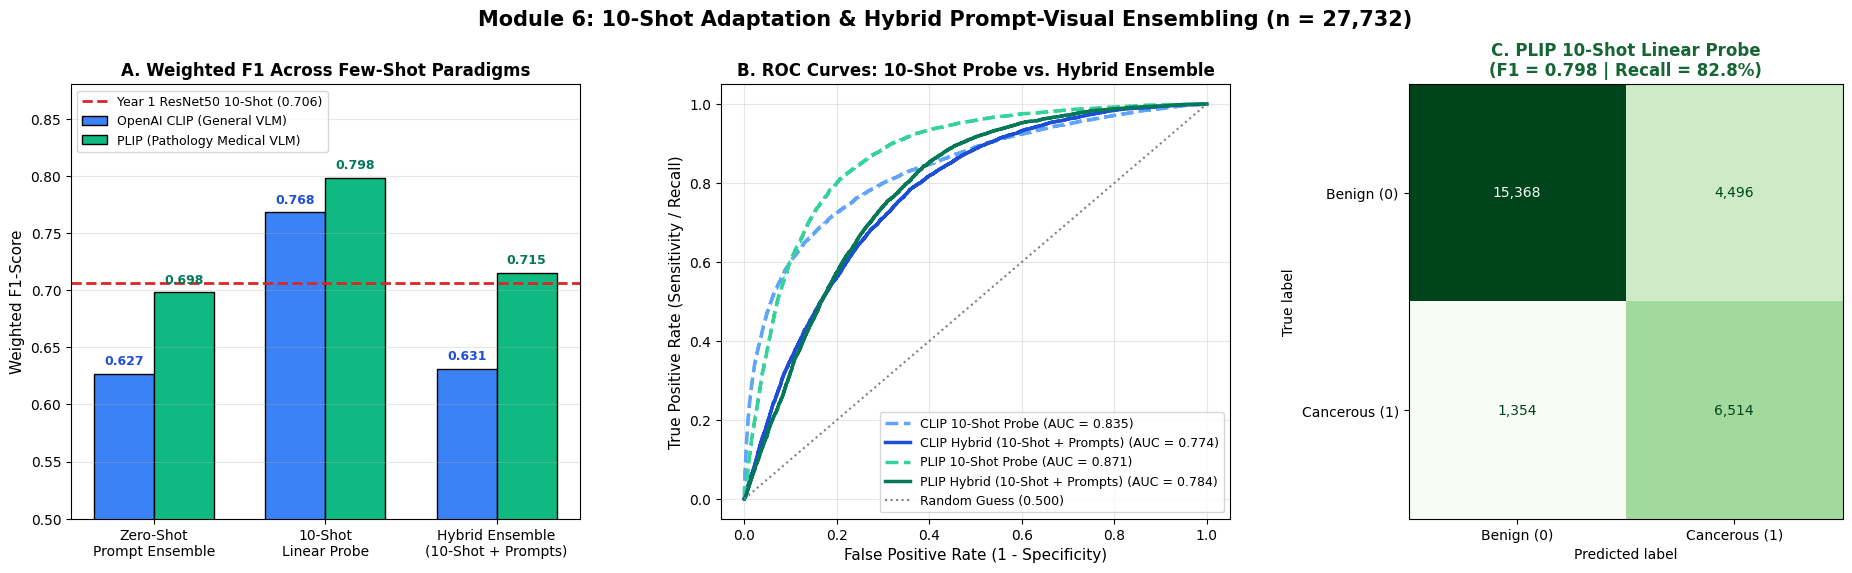

✅ High-resolution Module 6 figure saved to: /content/drive/My Drive/Sophomore Program/2-Results/Module6_FewShot_and_Ensemble_Comparison.png


In [5]:
# ==============================================================================
# MODULE 6 - STEP 5: PLOT PUBLICATION-READY 10-SHOT & HYBRID ENSEMBLE FIGURES
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
fig.suptitle("Module 6: 10-Shot Adaptation & Hybrid Prompt-Visual Ensembling (n = 27,732)", fontsize=15, fontweight="bold")

# 1. Left Plot: Grouped Bar Chart of Weighted F1-Scores
paradigm_labels = ["Zero-Shot\nPrompt Ensemble", "10-Shot\nLinear Probe", "Hybrid Ensemble\n(10-Shot + Prompts)"]
clip_m6_f1 = results_m6_df[results_m6_df["Model Architecture"].str.contains("OpenAI CLIP")]["Weighted F1"].values
plip_m6_f1 = results_m6_df[results_m6_df["Model Architecture"].str.contains("PLIP")]["Weighted F1"].values

x = np.arange(len(paradigm_labels))
width = 0.35

b1 = axes[0].bar(x - width/2, clip_m6_f1, width, label="OpenAI CLIP (General VLM)", color="#3B82F6", edgecolor="black")
b2 = axes[0].bar(x + width/2, plip_m6_f1, width, label="PLIP (Pathology Medical VLM)", color="#10B981", edgecolor="black")
axes[0].axhline(0.706, color="#DC2626", linestyle="--", lw=2, label="Year 1 ResNet50 10-Shot (0.706)")

axes[0].set_title("A. Weighted F1 Across Few-Shot Paradigms", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Weighted F1-Score", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(paradigm_labels, fontsize=10)
axes[0].set_ylim(0.50, 0.88)
axes[0].legend(loc="upper left", fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

for bar in b1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008, f"{bar.get_height():.3f}", ha="center", fontsize=9, fontweight="bold", color="#1D4ED8")
for bar in b2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008, f"{bar.get_height():.3f}", ha="center", fontsize=9, fontweight="bold", color="#047857")

# 2. Middle Plot: ROC Curves Comparing CLIP vs. PLIP (10-Shot & Hybrid)
roc_configs = [
    ("CLIP 10-Shot Probe", clip_10shot_probs, "#60A5FA", "--"),
    ("CLIP Hybrid (10-Shot + Prompts)", clip_hybrid_probs, "#1D4ED8", "-"),
    ("PLIP 10-Shot Probe", plip_10shot_probs, "#34D399", "--"),
    ("PLIP Hybrid (10-Shot + Prompts)", plip_hybrid_probs, "#047857", "-"),
]

for label_txt, probs_arr, col, ls in roc_configs:
    fpr, tpr, _ = roc_curve(eval_y, probs_arr)
    auc_v = roc_auc_score(eval_y, probs_arr)
    axes[1].plot(fpr, tpr, color=col, linestyle=ls, lw=2.5, label=f"{label_txt} (AUC = {auc_v:.3f})")

axes[1].plot([0, 1], [0, 1], color="gray", lw=1.5, linestyle=":", label="Random Guess (0.500)")
axes[1].set_title("B. ROC Curves: 10-Shot Probe vs. Hybrid Ensemble", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(alpha=0.3)

# 3. Right Plot: Confusion Matrix for Best Overall Model in Module 6
best_probs = plip_hybrid_probs if f1_score(eval_y, (plip_hybrid_probs >= 0.5).astype(int), average="weighted") >= f1_score(eval_y, (plip_10shot_probs >= 0.5).astype(int), average="weighted") else plip_10shot_probs
best_title = "PLIP Hybrid (10-Shot + Prompts)" if best_probs is plip_hybrid_probs else "PLIP 10-Shot Linear Probe"
best_preds = (best_probs >= 0.5).astype(int)
best_f1 = f1_score(eval_y, best_preds, average="weighted")
best_rec = recall_score(eval_y, best_preds) * 100

cm_best = confusion_matrix(eval_y, best_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=["Benign (0)", "Cancerous (1)"])
disp.plot(ax=axes[2], cmap="Greens", colorbar=False, values_format=",d")
axes[2].set_title(f"C. {best_title}\n(F1 = {best_f1:.3f} | Recall = {best_rec:.1f}%)", fontsize=12, fontweight="bold", color="#166534")

plt.tight_layout()
fig_m6_path = os.path.join(DRIVE_RESULTS_DIR, "Module6_FewShot_and_Ensemble_Comparison.png")
plt.savefig(fig_m6_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ High-resolution Module 6 figure saved to: {fig_m6_path}")